In [13]:
import pandas as pd

# Load dataset hasil preprocessing Minggu 5
df_model = pd.read_csv('/content/titanic_model_ready.csv')
df_model.head()

,survived,pclass,sex,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,sex_encoded,embarked_C,embarked_Q,embarked_S,family_size,kategori_usia
0,0,3,male,-0.565736,1,0,-0.502445,Third,man,True,Southampton,no,False,1,False,False,True,0.059160,Dewasa
1,1,1,female,0.663861,1,0,0.786845,First,woman,False,Cherbourg,yes,False,0,True,False,False,0.059160,Dewasa
2,1,3,female,-0.258337,0,0,-0.488854,Third,woman,False,Southampton,yes,True,0,False,False,True,-0.560975,Dewasa
3,1,1,female,0.433312,1,0,0.420730,First,woman,False,Southampton,yes,False,0,False,False,True,0.059160,Dewasa
4,0,3,male,0.433312,0,0,-0.486337,Third,man,True,Southampton,no,True,1,False,False,True,-0.560975,Dewasa


In [14]:
fitur = ['pclass', 'sex_encoded', 'age', 'fare', 'family_size']
target = 'survived'
X = df_model[fitur]
y = df_model[target]

print('Fitur yang digunakan:', fitur)
print('Target yang diprediksi:', target)

Fitur yang digunakan: ['pclass', 'sex_encoded', 'age', 'fare', 'family_size']
Target yang diprediksi: survived


In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, random_state=42
)

print('Data training:', X_train.shape)
print('Data testing :', X_test.shape)

Data training: (712, 5)
Data testing : (179, 5)


In [16]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model_lr = LogisticRegression(max_iter=1000)
model_lr.fit(X_train, y_train)
y_pred_lr = model_lr.predict(X_test)
akurasi_lr = accuracy_score(y_test, y_pred_lr)

print('Akurasi Logistic Regression:', round(akurasi_lr, 4))

Akurasi Logistic Regression: 0.8045


In [17]:
from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(max_depth=5, random_state=42)
model_dt.fit(X_train, y_train)
y_pred_dt = model_dt.predict(X_test)
akurasi_dt = accuracy_score(y_test, y_pred_dt)

print('Akurasi Decision Tree:', round(akurasi_dt, 4))

Akurasi Decision Tree: 0.8045


In [18]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
model_rf.fit(X_train, y_train)
y_pred_rf = model_rf.predict(X_test)
akurasi_rf = accuracy_score(y_test, y_pred_rf)

print('Akurasi Random Forest:', round(akurasi_rf, 4))

Akurasi Random Forest: 0.8045


In [19]:
hasil_perbandingan = pd.DataFrame({
 'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
 'Akurasi': [akurasi_lr, akurasi_dt, akurasi_rf]
})

print(hasil_perbandingan.sort_values('Akurasi', ascending=False))

                 Model   Akurasi
0  Logistic Regression  0.804469
1        Decision Tree  0.804469
2        Random Forest  0.804469


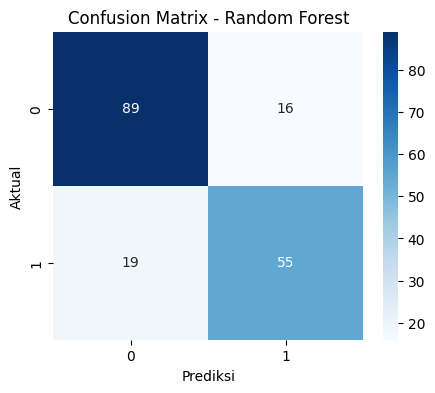

              precision    recall  f1-score   support

           0       0.82      0.85      0.84       105
           1       0.77      0.74      0.76        74

    accuracy                           0.80       179
   macro avg       0.80      0.80      0.80       179
weighted avg       0.80      0.80      0.80       179



In [20]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()

print(classification_report(y_test, y_pred_rf))

In [21]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Scaling ulang untuk memastikan data sesuai untuk ANN
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Data siap digunakan untuk pelatihan ANN.')
print('Shape X_train:', X_train_scaled.shape)

Data siap digunakan untuk pelatihan ANN.
Shape X_train: (712, 5)


In [22]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

model_ann = keras.Sequential([
 layers.Dense(16, activation='relu', input_shape=(X_train_scaled.shape[1],)),
 layers.Dense(8, activation='relu'),
 layers.Dense(1, activation='sigmoid') # sigmoid untuk klasifikasi biner
])

model_ann.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
model_ann.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 241 (964.00 B)

 Trainable params: 241 (964.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6450 - loss: 0.6551 - val_accuracy: 0.7972 - val_loss: 0.6340
Epoch 2/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7803 - loss: 0.6154 - val_accuracy: 0.8182 - val_loss: 0.5960
Epoch 3/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7873 - loss: 0.5809 - val_accuracy: 0.8252 - val_loss: 0.5582
Epoch 4/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7996 - loss: 0.5474 - val_accuracy: 0.8252 - val_loss: 0.5206
Epoch 5/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8014 - loss: 0.5177 - val_accuracy: 0.8322 - val_loss: 0.4877
Epoch 6/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7996 - loss: 0.4933 - val_accuracy: 0.8322 - val_loss: 0.4602
Epoch 7/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8014 - loss: 0.4742 - val_accuracy: 0.8252 - val_loss: 0.4396
Epoch 8/50
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8014 - loss: 0.4600 - val_accuracy: 0.8252 - val_loss:

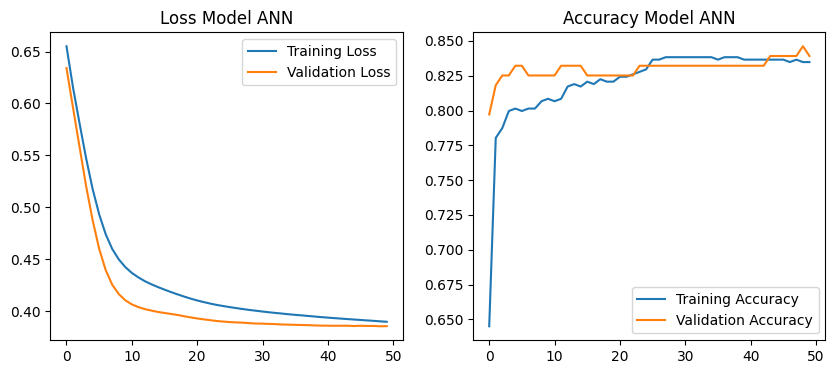

In [23]:
history = model_ann.fit(
 X_train_scaled, y_train,
 epochs=50,
 batch_size=16,
 validation_split=0.2,
 verbose=1
)

import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Loss Model ANN')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Model ANN')
plt.legend()
plt.show()

In [24]:
loss_ann, akurasi_ann = model_ann.evaluate(X_test_scaled, y_test, verbose=0)

print('Akurasi ANN pada data testing:', round(akurasi_ann, 4))

# Bandingkan dengan hasil Machine Learning sebelumnya
hasil_final = pd.DataFrame({'Model': [
    'Logistic Regression',
    'Decision Tree',
    'Random Forest',
    'ANN (Deep Learning)'],
 'Akurasi': [akurasi_lr, akurasi_dt, akurasi_rf, akurasi_ann]
})

print(hasil_final.sort_values('Akurasi', ascending=False))

Akurasi ANN pada data testing: 0.8268
                 Model   Akurasi
3  ANN (Deep Learning)  0.826816
0  Logistic Regression  0.804469
1        Decision Tree  0.804469
2        Random Forest  0.804469


In [25]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Memuat dataset MNIST (citra angka tulisan tangan 28x28 piksel, grayscale)
(X_train_img, y_train_img), (X_test_img, y_test_img) = keras.datasets.mnist.load_data()

# Normalisasi nilai piksel ke rentang 0-1
X_train_img = X_train_img.astype('float32') / 255.0
X_test_img = X_test_img.astype('float32') / 255.0

# Reshape agar sesuai input CNN: (jumlah_data, tinggi, lebar, channel)
X_train_img = X_train_img.reshape(-1, 28, 28, 1)
X_test_img = X_test_img.reshape(-1, 28, 28, 1)

print('Shape data training citra:', X_train_img.shape)
print('Jumlah kelas (digit 0-9):', len(set(y_train_img)))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shape data training citra: (60000, 28, 28, 1)
Jumlah kelas (digit 0-9): 10


In [26]:
model_cnn = keras.Sequential([
 layers.Conv2D(32, kernel_size=(3,3), activation='relu', input_shape=(28,28,1)),
 layers.MaxPooling2D(pool_size=(2,2)),
 layers.Conv2D(64, kernel_size=(3,3), activation='relu'),
 layers.MaxPooling2D(pool_size=(2,2)),
 layers.Flatten(),
 layers.Dense(64, activation='relu'),
 layers.Dense(10, activation='softmax') # 10 kelas: digit 0-9
])

model_cnn.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
model_cnn.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 10s 37ms/step - accuracy: 0.8591 - loss: 0.4648 - val_accuracy: 0.9485 - val_loss: 0.1890
Epoch 2/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 28ms/step - accuracy: 0.9599 - loss: 0.1333 - val_accuracy: 0.9525 - val_loss: 0.1524
Epoch 3/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.9729 - loss: 0.0909 - val_accuracy: 0.9520 - val_loss: 0.1595
Epoch 4/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 9s 35ms/step - accuracy: 0.9820 - loss: 0.0642 - val_accuracy: 0.9555 - val_loss: 0.1541
Epoch 5/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - accuracy: 0.9891 - loss: 0.0421 - val_accuracy: 0.9550 - val_loss: 0.1545
Akurasi CNN pada data testing MNIST: 0.97


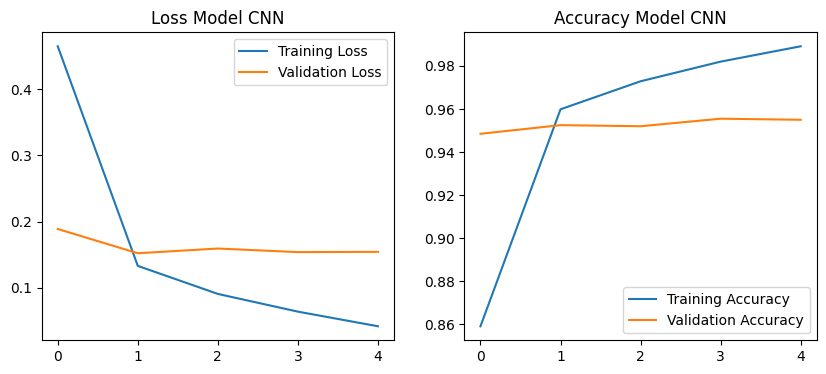

In [27]:
# Gunakan subset data agar pelatihan lebih cepat
history_cnn = model_cnn.fit(
 X_train_img[:10000], y_train_img[:10000],
 epochs=5,
 batch_size=32,
 validation_split=0.2,
 verbose=1
)

loss_cnn, akurasi_cnn = model_cnn.evaluate(X_test_img, y_test_img, verbose=0)

print('Akurasi CNN pada data testing MNIST:', round(akurasi_cnn, 4))

import matplotlib.pyplot as plt

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.plot(history_cnn.history['loss'], label='Training Loss')
plt.plot(history_cnn.history['val_loss'], label='Validation Loss')
plt.title('Loss Model CNN'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history_cnn.history['accuracy'], label='Training Accuracy')
plt.plot(history_cnn.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Model CNN'); plt.legend()
plt.show()

In [28]:
import numpy as np

# Membangkitkan data deret waktu sintetis berupa gelombang sinus
waktu = np.arange(0, 200, 0.5)
deret = np.sin(waktu) + np.random.normal(0, 0.1, len(waktu)) # tambahkan sedikit noise

def buat_windowing(data, window_size=10):
 """Mengubah deret waktu menjadi pasangan (X, y) dengan teknik sliding window."""
 X, y = [], []
 for i in range(len(data) - window_size):
  X.append(data[i:i + window_size])
  y.append(data[i + window_size])
 return np.array(X), np.array(y)

window_size = 10
X_ts, y_ts = buat_windowing(deret, window_size)

# Bagi data menjadi training dan testing (80:20, tanpa acak karena data time series)
split_idx = int(len(X_ts) * 0.8)
X_train_ts, X_test_ts = X_ts[:split_idx], X_ts[split_idx:]
y_train_ts, y_test_ts = y_ts[:split_idx], y_ts[split_idx:]

# Reshape agar sesuai input LSTM: (jumlah_sampel, window_size, jumlah_fitur)
X_train_ts = X_train_ts.reshape((X_train_ts.shape[0], window_size, 1))
X_test_ts = X_test_ts.reshape((X_test_ts.shape[0], window_size, 1))

print('Shape data training LSTM:', X_train_ts.shape)

Shape data training LSTM: (312, 10, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - loss: 0.4756 - mae: 0.6203 - val_loss: 0.4419 - val_mae: 0.5891
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.3645 - mae: 0.5404 - val_loss: 0.2799 - val_mae: 0.4590
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.1813 - mae: 0.3643 - val_loss: 0.1027 - val_mae: 0.2634
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0559 - mae: 0.1879 - val_loss: 0.0292 - val_mae: 0.1304
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0289 - mae: 0.1377 - val_loss: 0.0226 - val_mae: 0.1243
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0230 - mae: 0.1223 - val_loss: 0.0195 - val_mae: 0.1142
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0202 - mae: 0.1124 - val_loss: 0.0189 - val_mae: 0.1127
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0194 - mae: 0.1103 - val_loss: 0.0184 - val_mae: 0.1119
Epoch 9/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.019

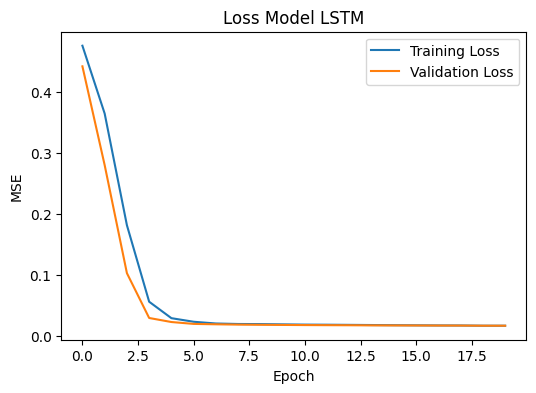

In [29]:
from tensorflow.keras import layers, models

model_lstm = models.Sequential([
 layers.LSTM(32, activation='tanh', input_shape=(window_size, 1)),
 layers.Dense(16, activation='relu'),
 layers.Dense(1) # output berupa nilai kontinu (regresi)
])

model_lstm.compile(optimizer='adam', loss='mse', metrics=['mae'])
model_lstm.summary()

history_lstm = model_lstm.fit(
 X_train_ts, y_train_ts,
 epochs=20,
 batch_size=16,
 validation_split=0.2,
 verbose=1
)

# Tambahan: grafik loss selama training
import matplotlib.pyplot as plt

plt.figure(figsize=(6,4))
plt.plot(history_lstm.history['loss'], label='Training Loss')
plt.plot(history_lstm.history['val_loss'], label='Validation Loss')
plt.title('Loss Model LSTM'); plt.xlabel('Epoch'); plt.ylabel('MSE'); plt.legend()
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step


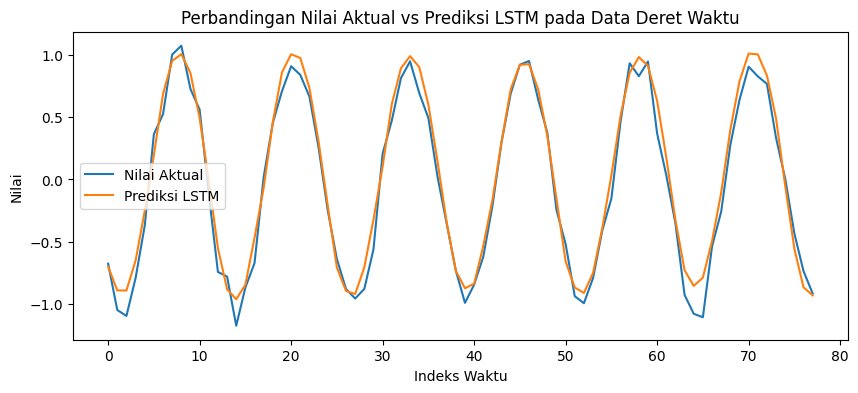

MSE dan MAE model LSTM pada data testing: [0.015154615044593811, 0.10164327174425125]


In [34]:
import matplotlib.pyplot as plt

y_pred_ts = model_lstm.predict(X_test_ts)

plt.figure(figsize=(10,4))
plt.plot(y_test_ts, label='Nilai Aktual')
plt.plot(y_pred_ts, label='Prediksi LSTM')
plt.title('Perbandingan Nilai Aktual vs Prediksi LSTM pada Data Deret Waktu')
plt.xlabel('Indeks Waktu')
plt.ylabel('Nilai')
plt.legend()
plt.show()

mse_lstm = model_lstm.evaluate(X_test_ts, y_test_ts, verbose=0)

print('MSE dan MAE model LSTM pada data testing:', mse_lstm)


PRAKTIKUM 2